# Лабораторная работа №2. Классификация CIFAR-10

**Студент:** Мальцев Максим Константинович  
**Группа:** 3825М1ПР1

**Цель:** разработать и обучить свёрточную нейронную сеть для классификации цветных изображений CIFAR-10.

In [1]:
import copy
import time

import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Устройство:", device)

PyTorch: 2.11.0
Устройство: mps


## 1. Данные и параметры

CIFAR-10 содержит 50 000 обучающих и 10 000 тестовых изображений. Из обучающих случайно выделяем 5 000 для валидации: по ней выбираем эпоху, а тест используем для итоговой оценки.

Для обучения применяем случайный сдвиг и отражение, затем переводим изображения в тензоры и нормализуем каждый канал: `(x − 0,5) / 0,5`. При оценке случайных преобразований нет. 

In [9]:
batch_size = 128
epochs = 30
learning_rate = 0.005
weight_decay = 0.0005

train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])
eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])

train_source = datasets.CIFAR10(root="./data", train=True, download=True, transform=train_transform)
eval_source = datasets.CIFAR10(root="./data", train=True, download=False, transform=eval_transform)
test_data = datasets.CIFAR10(root="./data", train=False, download=True, transform=eval_transform)

indices = torch.randperm(len(train_source)).tolist()
val_indices = indices[:5000]
train_indices = indices[5000:]

train_data = Subset(train_source, train_indices)
train_eval_data = Subset(eval_source, train_indices)
val_data = Subset(eval_source, val_indices)

train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True, num_workers=0)
train_eval_loader = DataLoader(train_eval_data, batch_size=batch_size, shuffle=False, num_workers=0)
val_loader = DataLoader(val_data, batch_size=batch_size, shuffle=False, num_workers=0)
test_loader = DataLoader(test_data, batch_size=batch_size, shuffle=False, num_workers=0)

image, label = test_data[0]
print("Примеров: train =", len(train_data), ", validation =", len(val_data), ", test =", len(test_data))
print("Форма изображения (C, H, W):", tuple(image.shape))
print("Метка:", label, ", тип:", type(label).__name__, ", класс:", test_data.classes[label])
print("Классы:", test_data.classes)

Примеров: train = 45000 , validation = 5000 , test = 10000
Форма изображения (C, H, W): (3, 32, 32)
Метка: 3 , тип: int , класс: cat
Форма батча изображений: (128, 3, 32, 32)
Форма батча меток: (128,) , тип: torch.int64
Классы: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


Посмотрим на несколько изображений из тестовой выборки. Для отображения отменяем нормализацию.

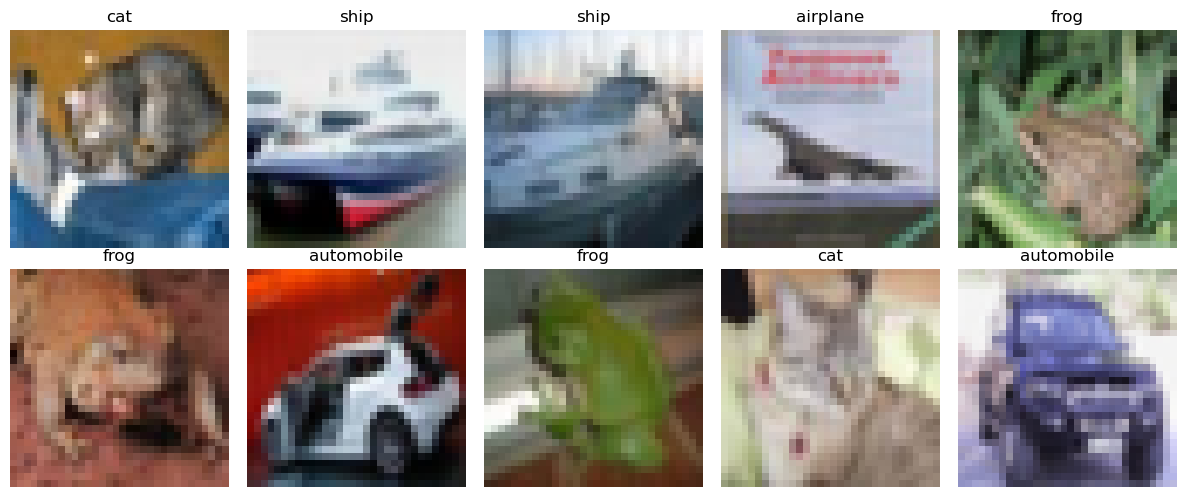

In [10]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.flat):
    image, label = test_data[i]
    image = image * 0.5 + 0.5
    ax.imshow(image.permute(1, 2, 0).clamp(0, 1))
    ax.set_title(test_data.classes[label])
    ax.axis("off")
plt.tight_layout()
plt.show()

## 2. Свёрточная сеть

В каждом блоке — две свёртки 3×3, после них MaxPool уменьшает высоту и ширину вдвое:

`3×32×32 → 32×16×16 → 64×8×8 → 128×4×4 → 128 → 10`.

После каждой свёртки BatchNorm нормализует активации, а ReLU добавляет нелинейность. Dropout на обучении случайно обнуляет часть значений перед последним слоем. На выходе получаем 10 **логитов**; отдельный softmax не нужен, потому что `CrossEntropyLoss` работает непосредственно с логитами.

In [11]:
class ImageClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

model = ImageClassifier().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=weight_decay)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

print(model)
print("Обучаемых параметров:", sum(p.numel() for p in model.parameters() if p.requires_grad))

ImageClassifier(
  (feature_extractor): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (9): ReLU()
    (10): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (12): ReLU()
    (13): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (14): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 

## 3. Обучение

После каждой эпохи отдельно оцениваем то, что получилось на валидационной выборке с текущими весами и без аугментации.

В итоговом тесте используем веса эпохи с лучшей точностью на валидации. Тестовая выборка не участвует в выборе эпохи.

In [12]:
def evaluate(loader):
    model.eval()
    total_loss = 0.0
    correct = 0
    count = 0

    with torch.inference_mode():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            logits = model(images)
            loss = criterion(logits, labels)
            n = labels.size(0)
            total_loss += loss.item() * n
            correct += (logits.argmax(dim=1) == labels).sum().item()
            count += n

    return total_loss / count, correct / count

In [13]:
history = {"train_loss": [], "train_accuracy": [], "val_loss": [], "val_accuracy": []}
best_accuracy = -1.0
best_epoch = 0
best_state = None

for epoch in range(epochs):
    start = time.time()
    model.train()

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

    train_loss, train_accuracy = evaluate(train_eval_loader)
    val_loss, val_accuracy = evaluate(val_loader)
    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)

    if val_accuracy > best_accuracy:
        best_accuracy = val_accuracy
        best_epoch = epoch + 1
        best_state = copy.deepcopy(model.state_dict())

    print(f"Эпоха {epoch + 1:2d}/{epochs}: "
          f"train loss={train_loss:.4f}, точность={train_accuracy:.2%}, ошибка={1 - train_accuracy:.2%}; "
          f"val loss={val_loss:.4f}, точность={val_accuracy:.2%}, ошибка={1 - val_accuracy:.2%}; "
          f"время={time.time() - start:.1f} с", flush=True)
    scheduler.step()

print(f"Лучшая эпоха по validation: {best_epoch}, точность={best_accuracy:.2%}")

Эпоха  1/30: train loss=1.8025, точность=31.15%, ошибка=68.85%; val loss=1.8164, точность=30.54%, ошибка=69.46%; время=13.6 с
Эпоха  2/30: train loss=1.5858, точность=40.62%, ошибка=59.38%; val loss=1.5768, точность=40.20%, ошибка=59.80%; время=13.5 с
Эпоха  3/30: train loss=1.2635, точность=54.32%, ошибка=45.68%; val loss=1.2570, точность=53.72%, ошибка=46.28%; время=14.8 с
Эпоха  4/30: train loss=1.0652, точность=61.35%, ошибка=38.65%; val loss=1.0934, точность=60.34%, ошибка=39.66%; время=14.5 с
Эпоха  5/30: train loss=0.9298, точность=67.35%, ошибка=32.65%; val loss=0.9535, точность=66.80%, ошибка=33.20%; время=13.9 с
Эпоха  6/30: train loss=0.9376, точность=67.82%, ошибка=32.18%; val loss=0.9792, точность=66.92%, ошибка=33.08%; время=13.6 с
Эпоха  7/30: train loss=0.7546, точность=72.99%, ошибка=27.01%; val loss=0.7899, точность=71.50%, ошибка=28.50%; время=13.4 с
Эпоха  8/30: train loss=0.6394, точность=78.14%, ошибка=21.86%; val loss=0.6598, точность=77.24%, ошибка=22.76%; время

## 4. Графики обучения

Сравниваем кросс-энтропию и ошибку классификации на обучающей и валидационной выборках.

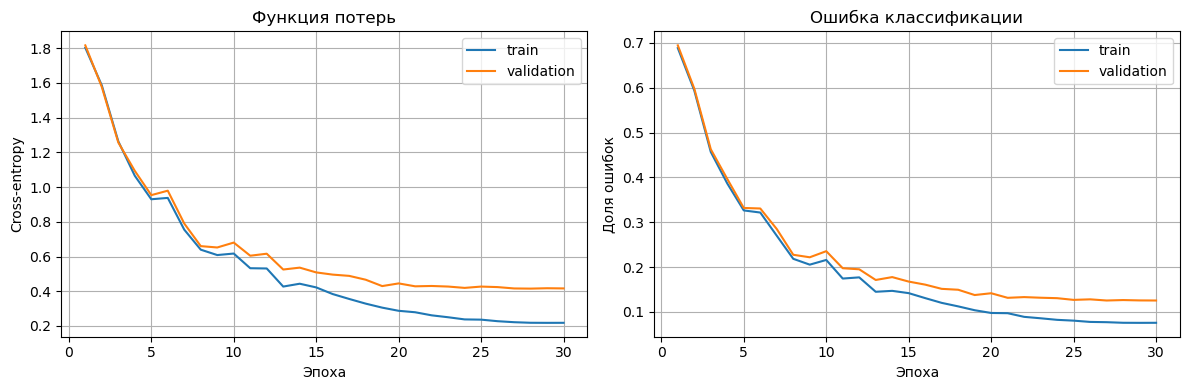

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
epoch_numbers = range(1, len(history["train_loss"]) + 1)
axes[0].plot(epoch_numbers, history["train_loss"], label="train")
axes[0].plot(epoch_numbers, history["val_loss"], label="validation")
axes[0].set(xlabel="Эпоха", ylabel="Cross-entropy", title="Функция потерь")
axes[1].plot(epoch_numbers, [1 - acc for acc in history["train_accuracy"]], label="train")
axes[1].plot(epoch_numbers, [1 - acc for acc in history["val_accuracy"]], label="validation")
axes[1].set(xlabel="Эпоха", ylabel="Доля ошибок", title="Ошибка классификации")
for ax in axes:
    ax.grid(True)
    ax.legend()
plt.tight_layout()
plt.show()

## 5. Итоговая оценка на тесте

Восстанавливаем веса лучшей эпохи и вычисляем метрики для 10 000 тестовых изображений. Тест уже использовался в предыдущих экспериментах; при дальнейшем выборе модели по тесту оценка становится менее независимой.

In [15]:
model.load_state_dict(best_state)
test_loss, test_accuracy = evaluate(test_loader)
print(f"Лучшая эпоха: {best_epoch}")
print(f"Тест: loss={test_loss:.4f}, точность={test_accuracy:.2%}, "
      f"ошибка классификации={1 - test_accuracy:.2%}")

Лучшая эпоха: 27
Тест: loss=0.4416, точность=86.88%, ошибка классификации=13.12%
